In [4]:
!pip install torch torchvision scikit-learn matplotlib seaborn pandas pillow tqdm

In [5]:
import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cuda
PyTorch version: 2.11.0+cu130


In [8]:
import pandas as pd
df = pd.read_csv("hmnist_28_28_L.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns)

Dataset shape: (4008, 785)
   pixel0000  pixel0001  pixel0002  pixel0003  pixel0004  pixel0005  \
0        101        110        154        160         95         44   
1         67         66         69         76         80         57   
2        127        137        121        140        170        111   
3         80         90        101        106        120        100   
4        153        141        121        132        110        131   

   pixel0006  pixel0007  pixel0008  pixel0009  ...  pixel0775  pixel0776  \
0        139        184        164        160  ...      103.0       73.0   
1         46         67         90         77  ...       58.0       65.0   
2        128        117         60        105  ...       90.0      100.0   
3         99         66         63         91  ...      131.0      109.0   
4        119         99        101         91  ...      117.0      121.0   

   pixel0777  pixel0778  pixel0779  pixel0780  pixel0781  pixel0782  \
0       72.0      

In [9]:
#Separate pixels and labels
import numpy as np

X = df.drop("label", axis=1).values
y = df["label"].values

print("Images:", X.shape)
print("Labels:", y.shape)
print("Classes:", np.unique(y))

Images: (4008, 784)
Labels: (4008,)
Classes: [ 1.  2.  4.  5.  6.  7.  8. nan]


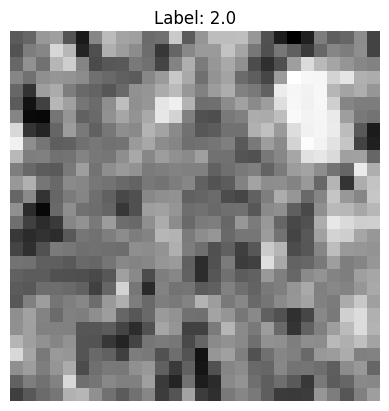

In [10]:
#Displaying an image
import matplotlib.pyplot as plt

image = X[0].reshape(28, 28)

plt.imshow(image, cmap="gray")
plt.title(f"Label: {y[0]}")
plt.axis("off")
plt.show()

In [11]:
import os
import zipfile
import urllib.request

zip_path = "/content/Kather_texture_2016_image_tiles_5000.zip"
extract_dir = "/content/colorectal_data"

url = (
    "https://zenodo.org/records/53169/files/"
    "Kather_texture_2016_image_tiles_5000.zip?download=1"
)

if not os.path.exists(zip_path):
    print("Downloading RGB dataset...")
    urllib.request.urlretrieve(url, zip_path)

print("Extracting images...")

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete!")

Extracting images...
Extraction complete!


In [12]:
from pathlib import Path

CLASS_NAMES = [
    "01_TUMOR",
    "02_STROMA",
    "03_COMPLEX",
    "04_LYMPHO",
    "05_DEBRIS",
    "06_MUCOSA",
    "07_ADIPOSE",
    "08_EMPTY"
]

root = Path("/content/colorectal_data")

DATA_DIR = None

for folder in root.rglob("01_TUMOR"):
    parent = folder.parent

    if all((parent / name).is_dir() for name in CLASS_NAMES):
        DATA_DIR = parent
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find all eight class folders. "
        "Inspect the extracted directory."
    )

print("RGB dataset path:", DATA_DIR)

for name in CLASS_NAMES:
    images = [
        p for p in (DATA_DIR / name).iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
    ]
    print(name, ":", len(images), "images")

RGB dataset path: /content/colorectal_data/Kather_texture_2016_image_tiles_5000
01_TUMOR : 625 images
02_STROMA : 625 images
03_COMPLEX : 625 images
04_LYMPHO : 625 images
05_DEBRIS : 625 images
06_MUCOSA : 625 images
07_ADIPOSE : 625 images
08_EMPTY : 625 images


Dataset: /content/colorectal_data/Kather_texture_2016_image_tiles_5000
01_TUMOR (150, 150) RGB
02_STROMA (150, 150) RGB
03_COMPLEX (150, 150) RGB
04_LYMPHO (150, 150) RGB
05_DEBRIS (150, 150) RGB
06_MUCOSA (150, 150) RGB
07_ADIPOSE (150, 150) RGB
08_EMPTY (150, 150) RGB


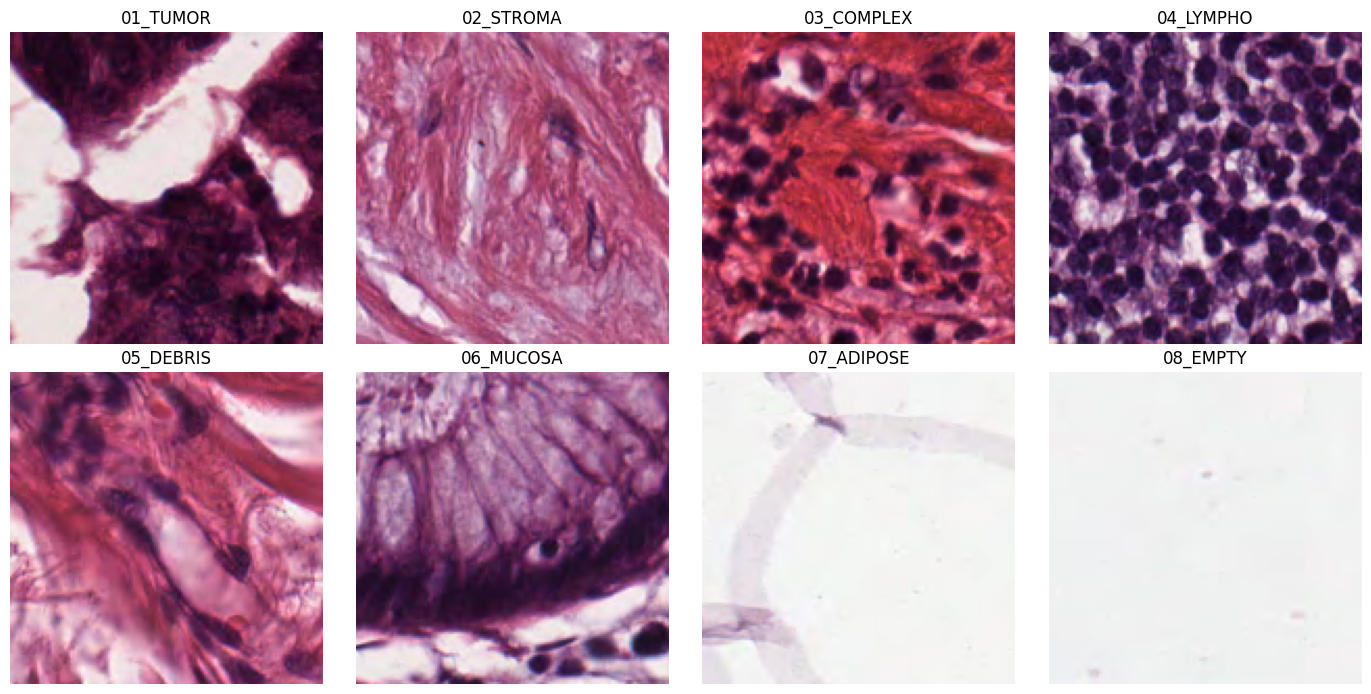

In [13]:
from PIL import Image
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "01_TUMOR", "02_STROMA", "03_COMPLEX", "04_LYMPHO",
    "05_DEBRIS", "06_MUCOSA", "07_ADIPOSE", "08_EMPTY"
]

print("Dataset:", DATA_DIR)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, class_name in enumerate(CLASS_NAMES):
    class_folder = DATA_DIR / class_name

    image_files = [
        p for p in class_folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
    ]

    with Image.open(image_files[0]) as img:
        img = img.convert("RGB")
        print(class_name, img.size, img.mode)
        axes.flat[i].imshow(img)

    axes.flat[i].set_title(class_name)
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [14]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
PyTorch version: 2.11.0+cu130
GPU: Tesla T4


In [15]:

from PIL import Image
from torch.utils.data import Dataset, DataLoader

class HistologyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = int(row["label"])

        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

print("HistologyDataset defined successfully!")


HistologyDataset defined successfully!


In [16]:
#Create the image transforms
from torchvision import transforms

# ImageNet normalization used with pretrained ResNet-18
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Transform for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270))
    ]),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Transform for validation images (no random augmentation)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training transform created!")
print("Validation transform created!")


Training transform created!
Validation transform created!


In [17]:

from PIL import Image
from torch.utils.data import Dataset, DataLoader

class HistologyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        required = {"image_path", "label"}
        missing = required - set(self.dataframe.columns)

        if missing:
            raise ValueError(
                f"Missing columns: {missing}. "
                f"Available columns: {self.dataframe.columns.tolist()}"
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

print("Dataset class updated!")


Dataset class updated!


In [18]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "/content/colorectal_data/Kather_texture_2016_image_tiles_5000"
)

class_folders = [
    "01_TUMOR",
    "02_STROMA",
    "03_COMPLEX",
    "04_LYMPHO",
    "05_DEBRIS",
    "06_MUCOSA",
    "07_ADIPOSE",
    "08_EMPTY"
]

records = []

for label, class_name in enumerate(class_folders):
    folder = DATA_DIR / class_name

    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")

    for image_path in folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]:
            records.append({
                "image_path": str(image_path),
                "label": label,
                "class_name": class_name
            })

df = pd.DataFrame(records)

print("Total RGB images:", len(df))
print("\nImages per class:")
print(df["class_name"].value_counts().sort_index())
print("\nColumns:", df.columns.tolist())
print("\nExample:")
print(df.iloc[0])


Total RGB images: 5000

Images per class:
class_name
01_TUMOR      625
02_STROMA     625
03_COMPLEX    625
04_LYMPHO     625
05_DEBRIS     625
06_MUCOSA     625
07_ADIPOSE    625
08_EMPTY      625
Name: count, dtype: int64

Columns: ['image_path', 'label', 'class_name']

Example:
image_path    /content/colorectal_data/Kather_texture_2016_i...
label                                                         0
class_name                                             01_TUMOR
Name: 0, dtype: object


In [19]:

from sklearn.model_selection import train_test_split

BASE_CLASSES = [1, 4, 6, 7]
NOVEL_CLASSES = [0, 2, 3, 5]

base_df = df[df["label"].isin(BASE_CLASSES)].copy()
novel_df = df[df["label"].isin(NOVEL_CLASSES)].copy()

train_df, val_df = train_test_split(
    base_df,
    test_size=0.20,
    random_state=42,
    stratify=base_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
novel_df = novel_df.reset_index(drop=True)

BASE_LABEL_MAP = {1: 0, 4: 1, 6: 2, 7: 3}

train_df_model = train_df.copy()
val_df_model = val_df.copy()

train_df_model["label"] = train_df_model["label"].map(BASE_LABEL_MAP)
val_df_model["label"] = val_df_model["label"].map(BASE_LABEL_MAP)

print("Training:", len(train_df_model))
print("Validation:", len(val_df_model))
print("Novel:", len(novel_df))


Training: 2000
Validation: 500
Novel: 2500


In [20]:

train_dataset = HistologyDataset(train_df_model, train_transform)
val_dataset = HistologyDataset(val_df_model, test_transform)

image, label = train_dataset[0]

print("Image tensor:", image.shape)
print("Label:", label)


Image tensor: torch.Size([3, 224, 224])
Label: 1


In [21]:
#Create DataLoaders

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Unique labels:", sorted(labels.unique().tolist()))


Images: torch.Size([16, 3, 224, 224])
Labels: torch.Size([16])
Unique labels: [0, 1, 2, 3]


In [22]:
#Load the pretrained ResNet-18 model

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace 1000 ImageNet outputs with our 4 base classes
model.fc = nn.Linear(model.fc.in_features, 4)

model = model.to(device)

print("ResNet-18 loaded successfully!")
print("Output classes:", model.fc.out_features)


Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


ResNet-18 loaded successfully!
Output classes: 4


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

In [24]:
#Train for five epochs

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss/train_total:.4f} | "
        f"Train Acc: {train_correct/train_total:.4f} | "
        f"Val Loss: {val_loss/val_total:.4f} | "
        f"Val Acc: {val_correct/val_total:.4f}"
    )

#Best validation accuracy   96.60%
#Epoch 3 · 483 out of 500 validation images correct

#Final training accuracy 96.55%
#Epoch 5

Epoch 1/5 | Train Loss: 0.2819 | Train Acc: 0.8935 | Val Loss: 0.1012 | Val Acc: 0.9580
Epoch 2/5 | Train Loss: 0.1512 | Train Acc: 0.9430 | Val Loss: 0.1193 | Val Acc: 0.9620
Epoch 3/5 | Train Loss: 0.1170 | Train Acc: 0.9570 | Val Loss: 0.0929 | Val Acc: 0.9660
Epoch 4/5 | Train Loss: 0.0991 | Train Acc: 0.9620 | Val Loss: 0.1444 | Val Acc: 0.9460
Epoch 5/5 | Train Loss: 0.1020 | Train Acc: 0.9655 | Val Loss: 0.1423 | Val Acc: 0.9520


In [25]:
#Saving our baseline

torch.save(
    model.state_dict(),
    "/content/resnet18_base_baseline.pth"
)

print("ResNet-18 baseline saved!")


ResNet-18 baseline saved!


In [26]:
model.fc = nn.Identity()
model.eval()

print("Feature extractor ready!")

Feature extractor ready!


In [ ]:
#4-way means four novel classes: TUMOR, COMPLEX, LYMPHO, and MUCOSA.
#1-shot means one labelled support image per class.
#5-shot means five labelled support images per class.
#10-shot means ten labelled support images per class.
#Each episode uses 15 separate query images per class to measure accuracy.

In [28]:

from torch.utils.data import DataLoader
import torch
import torch.nn as nn

# Make sure ResNet-18 is acting as a feature extractor
model.fc = nn.Identity()
model.eval()

# Select the four novel classes
novel_eval_df = novel_df.copy()

novel_dataset = HistologyDataset(
    novel_eval_df,
    transform=test_transform
)

novel_loader = DataLoader(
    novel_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

all_features = []
all_labels = []

with torch.no_grad():
    for images, labels in novel_loader:
        images = images.to(device)
        features = model(images)

        all_features.append(features.cpu())
        all_labels.append(labels.cpu())

novel_features = torch.cat(all_features)
novel_labels = torch.cat(all_labels)

print("Novel features shape:", novel_features.shape)
print("Novel labels shape:", novel_labels.shape)
print("Feature extraction complete!")


Novel features shape: torch.Size([2500, 512])
Novel labels shape: torch.Size([2500])
Feature extraction complete!


In [29]:

import random

# Reproducible experiments
random.seed(42)
torch.manual_seed(42)

# Original novel labels: 0, 2, 3, 5
# Remap them to consecutive labels: 0, 1, 2, 3
label_map = {0: 0, 2: 1, 3: 2, 5: 3}
mapped_labels = torch.tensor(
    [label_map[int(y)] for y in novel_labels.tolist()]
)

# Find the image indices for each of the 4 classes
class_indices = {
    c: torch.where(mapped_labels == c)[0].tolist()
    for c in range(4)
}

print("Images per novel class:")
for c, indices in class_indices.items():
    print(f"Class {c}: {len(indices)} images")

# Create 600 fixed episodes.
# Each episode has 10 possible support images
# and 15 separate query images per class.
NUM_EPISODES = 600
MAX_SHOT = 10
QUERIES_PER_CLASS = 15

episodes = []

for episode in range(NUM_EPISODES):
    episode_data = {}

    for c in range(4):
        chosen = random.sample(
            class_indices[c],
            MAX_SHOT + QUERIES_PER_CLASS
        )

        support_indices = chosen[:MAX_SHOT]
        query_indices = chosen[MAX_SHOT:]

        episode_data[c] = (support_indices, query_indices)

    episodes.append(episode_data)

print("\nCreated", len(episodes), "fixed episodes.")

# Use Euclidean distance to classify query images
features = novel_features.float()

results = {}

for shot in [1, 5, 10]:
    correct = 0
    total = 0

    for episode_data in episodes:
        prototypes = []
        query_features = []
        query_targets = []

        for c in range(4):
            support_idx, query_idx = episode_data[c]

            # Nested support sets: first 1, 5, or 10 images
            selected_support = support_idx[:shot]

            # Prototype = mean feature vector of support images
            prototype = features[selected_support].mean(dim=0)
            prototypes.append(prototype)

            query_features.append(features[query_idx])
            query_targets.extend([c] * len(query_idx))

        prototypes = torch.stack(prototypes)
        query_features = torch.cat(query_features)
        query_targets = torch.tensor(query_targets)

        # Shape: number of queries x 4 classes
        distances = torch.cdist(
            query_features,
            prototypes,
            p=2
        )

        predictions = distances.argmin(dim=1)

        correct += (predictions == query_targets).sum().item()
        total += len(query_targets)

    accuracy = 100 * correct / total
    results[shot] = accuracy

    print(
        f"{shot}-shot accuracy: {accuracy:.2f}% "
        f"({correct}/{total} queries correct)"
    )

print("\nFew-shot evaluation complete!")


Images per novel class:
Class 0: 625 images
Class 1: 625 images
Class 2: 625 images
Class 3: 625 images

Created 600 fixed episodes.
1-shot accuracy: 51.78% (18640/36000 queries correct)
5-shot accuracy: 67.14% (24171/36000 queries correct)
10-shot accuracy: 70.69% (25450/36000 queries correct)

Few-shot evaluation complete!


In [30]:
#Prototypical Networks · ResNet-18 features · 4 novel classes
#1-shot  51.78%
#5-shot   67.14%
#10-shot  70.69%
#Accuracy improves as the number of labelled support examples increases. From 1-shot to 10-shot, accuracy rises by 18.91 percentage points.

In [54]:
import math

features = novel_features.float()
episode_results = {}

for shot in [1, 5, 10]:
    accuracies = []

    for episode_data in episodes:
        prototypes = []
        query_features = []
        query_targets = []

        for c in range(4):
            support_idx, query_idx = episode_data[c]

            prototypes.append(
                features[support_idx[:shot]].mean(dim=0)
            )
            query_features.append(features[query_idx])
            query_targets.extend([c] * len(query_idx))

        prototypes = torch.stack(prototypes)
        query_features = torch.cat(query_features)
        query_targets = torch.tensor(query_targets)

        distances = torch.cdist(query_features, prototypes)
        predictions = distances.argmin(dim=1)

        accuracy = (
            (predictions == query_targets).float().mean().item()
            * 100
        )
        accuracies.append(accuracy)

    mean_acc = sum(accuracies) / len(accuracies)

    variance = sum(
        (x - mean_acc) ** 2 for x in accuracies
    ) / (len(accuracies) - 1)

    std_acc = math.sqrt(variance)
    ci = 1.96 * std_acc / math.sqrt(len(accuracies))

    episode_results[shot] = {
        "mean": mean_acc,
        "std": std_acc,
        "ci_low": mean_acc - ci,
        "ci_high": mean_acc + ci
    }

    print(
        f"{shot}-shot: {mean_acc:.2f}% "
        f"+/- {ci:.2f}% (95% CI)"
    )

print("\nConfidence interval calculation complete!")


1-shot: 51.78% +/- 0.87% (95% CI)
5-shot: 67.14% +/- 0.58% (95% CI)
10-shot: 70.69% +/- 0.52% (95% CI)

Confidence interval calculation complete!


In [55]:
results_df = pd.DataFrame({
    "Setting": ["1-shot", "5-shot", "10-shot"],
    "Mean Accuracy (%)": [51.78, 67.14, 70.69],
    "95% CI Lower (%)": [50.91, 66.56, 70.17],
    "95% CI Upper (%)": [52.65, 67.72, 71.21]
})

results_df.to_csv(
    "/content/few_shot_results.csv",
    index=False
)

print(results_df.to_string(index=False))
print("\nResults saved to /content/few_shot_results.csv")


Setting  Mean Accuracy (%)  95% CI Lower (%)  95% CI Upper (%)
 1-shot              51.78             50.91             52.65
 5-shot              67.14             66.56             67.72
10-shot              70.69             70.17             71.21

Results saved to /content/few_shot_results.csv


In [33]:

# Verify the few-shot evaluation protocol

assert len(episodes) == 600, "Expected 600 episodes"

for episode_num, episode_data in enumerate(episodes):
    for c in range(4):
        support_idx, query_idx = episode_data[c]

        # Check support/query sizes
        assert len(support_idx) == 10
        assert len(query_idx) == 15

        # No image should appear in both support and query
        assert set(support_idx).isdisjoint(set(query_idx))

        # Check that support and query images belong to this class
        assert all(mapped_labels[i].item() == c
                   for i in support_idx + query_idx)

print("Episode count: 600")
print("Classes per episode: 4")
print("Maximum support images per class: 10")
print("Query images per class: 15")
print("Support/query overlap: None")
print("Class assignments: Correct")
print("Protocol checks passed!")


Episode count: 600
Classes per episode: 4
Maximum support images per class: 10
Query images per class: 15
Support/query overlap: None
Class assignments: Correct
Protocol checks passed!


In [34]:

# Check nested support sets and identical query sets

for episode_num, episode_data in enumerate(episodes):
    for c in range(4):
        support_idx, query_idx = episode_data[c]

        # Query set must be separate from support
        assert len(query_idx) == 15
        assert set(support_idx).isdisjoint(set(query_idx))

        # First 1, 5, and 10 support images are nested
        support_1 = set(support_idx[:1])
        support_5 = set(support_idx[:5])
        support_10 = set(support_idx[:10])

        assert support_1.issubset(support_5)
        assert support_5.issubset(support_10)

print("Nested support sets: Verified")
print("Same query set across shot settings: Verified")
print("Evaluation protocol checks complete!")


Nested support sets: Verified
Same query set across shot settings: Verified
Evaluation protocol checks complete!


In [43]:

import os

REPO_URL = "https://github.com/Wajiha-144/Few-shot-colorectal-histology"
REPO_DIR = "/content/project_repo"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}

print("Repository available:", os.path.exists(REPO_DIR))


Cloning into '/content/project_repo'...
remote: Enumerating objects: 116, done.
remote: Counting objects: 100% (116/116), done.
remote: Compressing objects: 100% (105/105), done.
remote: Total 116 (delta 36), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (116/116), 10.43 MiB | 7.60 MiB/s, done.
Resolving deltas: 100% (36/36), done.
Repository available: True


In [47]:

# Inspect the dataset index and class labels
print("novel_df columns:", novel_df.columns.tolist())
print("\nFirst 5 rows:")
print(novel_df.head())

print("\nNovel label counts:")
print(novel_df["label"].value_counts().sort_index())

# Inspect official episode class labels
episode = test_episodes_A["1"][0]
print("\nOfficial episode classes:", episode["classes"])
print("Support indices:", episode["support"])
print("First query group:", episode["query"][0])

# Check whether all episode indices are valid positions
all_indices = []
for shot in ["1", "5", "10"]:
    for ep in test_episodes_A[shot]:
        for group in ep["support"]:
            all_indices.extend(group)
        for group in ep["query"]:
            all_indices.extend(group)

print("\nMinimum episode index:", min(all_indices))
print("Maximum episode index:", max(all_indices))
print("Number of novel dataset rows:", len(novel_df))
print("All indices within dataset bounds:",
      min(all_indices) >= 0 and max(all_indices) < len(novel_df))


novel_df columns: ['image_path', 'label', 'class_name']

First 5 rows:
                                          image_path  label class_name
0  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
1  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
2  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
3  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
4  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR

Novel label counts:
label
0    625
2    625
3    625
5    625
Name: count, dtype: int64

Official episode classes: [1, 4, 6, 3]
Support indices: [[255], [2241], [3585], [1864]]
First query group: [450, 487, 303, 512, 375, 225, 294, 364, 120, 532, 606, 173, 557, 305, 211]

Minimum episode index: 0
Maximum episode index: 3749
Number of novel dataset rows: 2500
All indices within dataset bounds: False


In [48]:

index_path = "/content/project_repo/data/processed/index_clean.csv"

if os.path.exists(index_path):
    official_index_df = pd.read_csv(index_path)

    print("Shape:", official_index_df.shape)
    print("Columns:", official_index_df.columns.tolist())
    print(official_index_df.head())
else:
    print("index_clean.csv was not found at the expected path.")


Shape: (5000, 4)
Columns: ['id', 'rel_path', 'label', 'class_name']
   id                                           rel_path  label  \
0   0  01_TUMOR/10009_CRC-Prim-HE-03_009.tif_Row_301_...      1   
1   1  01_TUMOR/10062_CRC-Prim-HE-02_003b.tif_Row_1_C...      1   
2   2  01_TUMOR/100B0_CRC-Prim-HE-09_009.tif_Row_1_Co...      1   
3   3  01_TUMOR/10104_CRC-Prim-HE-10_021.tif_Row_451_...      1   
4   4  01_TUMOR/10142_CRC-Prim-HE-09_025.tif_Row_151_...      1   

          class_name  
0  Tumour epithelium  
1  Tumour epithelium  
2  Tumour epithelium  
3  Tumour epithelium  
4  Tumour epithelium  


In [51]:

dataset_root = "/content/colorectal_data/Kather_texture_2016_image_tiles_5000"

import os

print("Dataset folder exists:", os.path.exists(dataset_root))


Dataset folder exists: True


In [52]:

import os
import numpy as np
import torch

# 1. Map each image path to its row in novel_df
def normalize_path(path):
    return os.path.normpath(str(path))

novel_path_to_row = {
    normalize_path(path): i
    for i, path in enumerate(novel_df["image_path"])
}

official_index_df["full_path"] = official_index_df["rel_path"].apply(
    lambda p: os.path.join(dataset_root, p)
)

id_to_feature_idx = {}

for _, row in official_index_df.iterrows():
    path = normalize_path(row["full_path"])
    if path in novel_path_to_row:
        id_to_feature_idx[int(row["id"])] = novel_path_to_row[path]

# 2. Verify feature and image counts
print("Novel feature shape:", novel_features.shape)
print("Novel dataframe rows:", len(novel_df))
print("Official IDs mapped to novel images:", len(id_to_feature_idx))

assert len(novel_features) == len(novel_df), (
    "Feature rows and novel_df rows do not match."
)

# 3. Verify every official test image can be mapped
missing_ids = set()

for shot in ["1", "5", "10"]:
    for ep in test_episodes_A[shot]:
        for group in ep["support"] + ep["query"]:
            for image_id in group:
                if image_id not in id_to_feature_idx:
                    missing_ids.add(image_id)

print("Unmapped episode image IDs:", len(missing_ids))

assert not missing_ids, (
    "Some episode images are not in novel_df. Do not evaluate yet."
)

print("Image-index mapping verified!")


Novel feature shape: torch.Size([2500, 512])
Novel dataframe rows: 2500
Official IDs mapped to novel images: 2500
Unmapped episode image IDs: 0
Image-index mapping verified!


In [57]:
#Finalized results — Split A
features = novel_features.detach().cpu().float()

for shot_key in ["1", "5", "10"]:
    episode_accuracies = []

    for ep in test_episodes_A[shot_key]:
        support_groups = ep["support"]
        query_groups = ep["query"]

        prototypes = []
        for support_ids in support_groups:
            rows = [id_to_feature_idx[int(i)] for i in support_ids]
            prototypes.append(features[rows].mean(dim=0))

        prototypes = torch.stack(prototypes)

        query_feature_groups = []
        query_labels = []

        for class_position, query_ids in enumerate(query_groups):
            rows = [id_to_feature_idx[int(i)] for i in query_ids]
            query_feature_groups.append(features[rows])
            query_labels.extend([class_position] * len(rows))

        query_features = torch.cat(query_feature_groups, dim=0)
        query_labels = torch.tensor(query_labels)

        distances = torch.cdist(query_features, prototypes, p=2)
        predictions = distances.argmin(dim=1)

        episode_accuracy = (
            predictions == query_labels
        ).float().mean().item()

        episode_accuracies.append(episode_accuracy)

    episode_accuracies = np.array(episode_accuracies)
    mean_acc = episode_accuracies.mean()
    ci = 1.96 * episode_accuracies.std(ddof=1) / np.sqrt(
        len(episode_accuracies)
    )

    print(
        f"{shot_key}-shot | "
        f"Accuracy: {mean_acc * 100:.2f}% | "
        f"95% CI: {((mean_acc-ci)*100):.2f}%–{((mean_acc+ci)*100):.2f}%"
    )


1-shot | Accuracy: 51.59% | 95% CI: 50.71%–52.47%
5-shot | Accuracy: 67.16% | 95% CI: 66.63%–67.70%
10-shot | Accuracy: 70.40% | 95% CI: 69.90%–70.90%


 What do these results mean?
- 1-shot: The model gets about 52 out of every 100 query images correct when given one support image per class.
- 5-shot: Accuracy improves to 67.16%.
- 10-shot: Accuracy reaches 70.40%.
- From 1-shot to 10-shot, accuracy improves by 18.81 percentage points

In [59]:
results_df = pd.DataFrame({
    "Split": ["A", "A", "A"],
    "Method": [
        "Frozen ResNet-18 + Mean Prototype",
        "Frozen ResNet-18 + Mean Prototype",
        "Frozen ResNet-18 + Mean Prototype"
    ],
    "Setting": ["1-shot", "5-shot", "10-shot"],
    "Mean Accuracy (%)": [51.59, 67.16, 70.40],
    "95% CI Lower (%)": [50.71, 66.63, 69.90],
    "95% CI Upper (%)": [52.47, 67.70, 70.90]
})

results_df.to_csv(
    "/content/few_shot_results.csv",
    index=False
)

print("\nOfficial Split A results saved.")



Official Split A results saved.


In [60]:
import torch.nn.functional as F

# Using the ResNet-18 features already extracted
features = novel_features.detach().cpu().float()

def matching_network_predict(
    support_features,
    support_labels,
    query_features
):
    # Normalizing features so we can use cosine similarity
    support_features = F.normalize(
        support_features, p=2, dim=1
    )
    query_features = F.normalize(
        query_features, p=2, dim=1
    )

    # Similarity of each query to every support image
    similarities = query_features @ support_features.T

    # Convert similarities into attention weights
    attention = torch.softmax(similarities * 10, dim=1)

    # Convert support labels to one-hot vectors
    num_classes = 4
    label_matrix = F.one_hot(
        support_labels, num_classes=num_classes
    ).float()

    # Add attention weights for each class
    class_scores = attention @ label_matrix

    return class_scores.argmax(dim=1)


results_matching = {}

for shot_key in ["1", "5", "10"]:
    episode_accuracies = []

    for ep in test_episodes_A[shot_key]:
        support_feature_groups = []
        support_label_groups = []
        query_feature_groups = []
        query_label_groups = []

        # Collect support and query features for each episode class
        for class_position, (support_ids, query_ids) in enumerate(
            zip(ep["support"], ep["query"])
        ):
            support_rows = [
                id_to_feature_idx[int(i)] for i in support_ids
            ]
            query_rows = [
                id_to_feature_idx[int(i)] for i in query_ids
            ]

            support_feature_groups.append(features[support_rows])
            support_label_groups.extend(
                [class_position] * len(support_rows)
            )

            query_feature_groups.append(features[query_rows])
            query_label_groups.extend(
                [class_position] * len(query_rows)
            )

        support_features = torch.cat(
            support_feature_groups, dim=0
        )
        support_labels = torch.tensor(support_label_groups)

        query_features = torch.cat(
            query_feature_groups, dim=0
        )
        query_labels = torch.tensor(query_label_groups)

        predictions = matching_network_predict(
            support_features,
            support_labels,
            query_features
        )

        accuracy = (
            predictions == query_labels
        ).float().mean().item()

        episode_accuracies.append(accuracy)

    episode_accuracies = np.array(episode_accuracies)

    mean_acc = episode_accuracies.mean()
    ci = (
        1.96 * episode_accuracies.std(ddof=1)
        / np.sqrt(len(episode_accuracies))
    )

    results_matching[shot_key] = {
        "accuracy": mean_acc * 100,
        "ci_lower": (mean_acc - ci) * 100,
        "ci_upper": (mean_acc + ci) * 100
    }

    print(
        f"{shot_key}-shot | "
        f"Accuracy: {mean_acc * 100:.2f}% | "
        f"95% CI: {(mean_acc-ci)*100:.2f}%–"
        f"{(mean_acc+ci)*100:.2f}%"
    )


1-shot | Accuracy: 53.74% | 95% CI: 52.85%–54.63%
5-shot | Accuracy: 69.00% | 95% CI: 68.43%–69.58%
10-shot | Accuracy: 73.34% | 95% CI: 72.81%–73.86%


In [62]:
comparison_rows = []

prototype_results = {
    "1": (51.59, 50.71, 52.47),
    "5": (67.16, 66.63, 67.70),
    "10": (70.40, 69.90, 70.90)
}

matching_results = {
    "1": (53.74, 52.85, 54.63),
    "5": (69.00, 68.43, 69.58),
    "10": (73.34, 72.81, 73.86)
}

for shot, values in prototype_results.items():
    comparison_rows.append({
        "Split": "A",
        "Method": "Frozen ResNet-18 + Mean Prototype",
        "Setting": f"{shot}-shot",
        "Accuracy (%)": values[0],
        "95% CI Lower (%)": values[1],
        "95% CI Upper (%)": values[2]
    })

for shot, values in matching_results.items():
    comparison_rows.append({
        "Split": "A",
        "Method": "Frozen ResNet-18 + Matching-style",
        "Setting": f"{shot}-shot",
        "Accuracy (%)": values[0],
        "95% CI Lower (%)": values[1],
        "95% CI Upper (%)": values[2]
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(
    "/content/split_A_baseline_comparison.csv",
    index=False
)
print("\nSaved to /content/split_A_baseline_comparison.csv")



Saved to /content/split_A_baseline_comparison.csv


This defines the small relation-scoring network. It accepts a 512-dimensional query feature and a 512-dimensional class prototype, combines them, and predicts a score between 0 and 1.

In [63]:
# Reuse the existing ResNet-18 features
features = novel_features.detach().cpu().float()

# Set reproducible random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

class RelationNetwork(nn.Module):
    def __init__(self, feature_dim=512, hidden_dim=256):
        super().__init__()

        self.relation = nn.Sequential(
            nn.Linear(feature_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, query_features, prototypes):
        # query_features: [number of queries, 512]
        # prototypes: [number of classes, 512]

        num_queries = query_features.size(0)
        num_classes = prototypes.size(0)

        queries = query_features.unsqueeze(1).expand(
            num_queries, num_classes, -1
        )

        class_prototypes = prototypes.unsqueeze(0).expand(
            num_queries, num_classes, -1
        )

        # Combine every query with every class prototype
        pairs = torch.cat(
            [queries, class_prototypes], dim=2
        )

        # Produce a relation score for each query-class pair
        scores = self.relation(pairs).squeeze(-1)

        return scores


relation_model = RelationNetwork()

print("Relation Network created successfully!")
print("Feature dimension:", features.shape[1])
print(
    "Trainable parameters:",
    sum(p.numel() for p in relation_model.parameters()
        if p.requires_grad)
)


Relation Network created successfully!
Feature dimension: 512
Trainable parameters: 278913


In [64]:

print("Base training dataframe exists:", "train_df" in globals())
print("Dataset class exists:", "HistologyDataset" in globals())
print("Base training dataset exists:", "train_dataset" in globals())
print("Feature extractor model exists:", "model" in globals())
print("Novel features exist:", "novel_features" in globals())


Base training dataframe exists: True
Dataset class exists: True
Base training dataset exists: True
Feature extractor model exists: True
Novel features exist: True


In [67]:

from torch.utils.data import DataLoader
import torch

# Automatically use the same device as the model
device = next(model.parameters()).device
model.eval()

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)

base_train_features = []
base_train_labels = []

with torch.no_grad():
    for images, labels in train_loader:
        # Move images to the model's device
        images = images.to(device)

        outputs = model(images)

        # Store extracted features and labels on the CPU
        base_train_features.append(outputs.cpu())
        base_train_labels.append(labels.cpu())

base_train_features = torch.cat(
    base_train_features, dim=0
).float()

base_train_labels = torch.cat(
    base_train_labels, dim=0
).long()

print("Model device:", device)
print("Base training features:", base_train_features.shape)
print("Base training labels:", base_train_labels.shape)
print("Unique base classes:", torch.unique(base_train_labels).tolist())
print("Feature extraction complete!")


Model device: cuda:0
Base training features: torch.Size([2000, 512])
Base training labels: torch.Size([2000])
Unique base classes: [0, 1, 2, 3]
Feature extraction complete!


Training the Relation Network

In [72]:
# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Use the GPU for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
relation_model = relation_model.to(device)

# Base training data stays separate from novel test data
train_features = base_train_features.float()
train_labels = base_train_labels.long()

# Find image indices belonging to each base class
base_class_indices = {
    int(c): torch.where(train_labels == c)[0].tolist()
    for c in torch.unique(train_labels)
}

print("Base class counts:", {
    c: len(indices) for c, indices in base_class_indices.items()
})

optimizer = torch.optim.Adam(
    relation_model.parameters(), lr=0.001
)
criterion = nn.MSELoss()

NUM_EPISODES = 500
N_WAY = 4
N_SUPPORT = 5
N_QUERY = 10

relation_model.train()

for episode_num in range(NUM_EPISODES):
    # Randomly select four base classes
    selected_classes = random.sample(
        list(base_class_indices.keys()), N_WAY
    )

    support_features = []
    support_labels = []
    query_features = []
    query_labels = []

    # Build the support and query sets
    for class_position, class_id in enumerate(selected_classes):
        chosen = random.sample(
            base_class_indices[class_id],
            N_SUPPORT + N_QUERY
        )

        support_ids = chosen[:N_SUPPORT]
        query_ids = chosen[N_SUPPORT:]

        support_features.append(train_features[support_ids])
        support_labels.extend(
            [class_position] * N_SUPPORT
        )

        query_features.append(train_features[query_ids])
        query_labels.extend(
            [class_position] * N_QUERY
        )

    support_features = torch.cat(support_features).to(device)
    query_features = torch.cat(query_features).to(device)

    support_labels = torch.tensor(
        support_labels, dtype=torch.long, device=device
    )
    query_labels = torch.tensor(
        query_labels, dtype=torch.long, device=device
    )

    # One mean prototype for each selected class
    prototypes = []

    for class_position in range(N_WAY):
        class_support = support_features[
            support_labels == class_position
        ]
        prototypes.append(class_support.mean(dim=0))

    prototypes = torch.stack(prototypes)

    # Predict relation scores for each query and class
    scores = relation_model(query_features, prototypes)

    # Target score: 1 for the correct class, 0 otherwise
    targets = F.one_hot(
        query_labels, num_classes=N_WAY
    ).float()

    loss = criterion(scores, targets)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (episode_num + 1) % 100 == 0:
        print(
            f"Episode {episode_num + 1}/{NUM_EPISODES} "
            f"| Loss: {loss.item():.4f}"
        )

print("Relation Network training complete!")


Base class counts: {0: 500, 1: 500, 2: 500, 3: 500}
Episode 100/500 | Loss: 0.0001
Episode 200/500 | Loss: 0.0000
Episode 300/500 | Loss: 0.0036
Episode 400/500 | Loss: 0.0003
Episode 500/500 | Loss: 0.0000
Relation Network training complete!


In [73]:
relation_model.eval()
features = novel_features.detach().cpu().float()

relation_results = {}

for shot_key in ["1", "5", "10"]:
    print(f"\nStarting {shot_key}-shot evaluation...", flush=True)

    episode_accuracies = []
    episodes = test_episodes_A[shot_key]

    for ep_num, ep in enumerate(episodes):
        prototypes = []

        for support_ids in ep["support"]:
            rows = [
                id_to_feature_idx[int(i)]
                for i in support_ids
            ]
            prototypes.append(features[rows].mean(dim=0))

        prototypes = torch.stack(prototypes).to(device)

        query_feature_groups = []
        query_labels = []

        for class_position, query_ids in enumerate(ep["query"]):
            rows = [
                id_to_feature_idx[int(i)]
                for i in query_ids
            ]
            query_feature_groups.append(features[rows])
            query_labels.extend(
                [class_position] * len(rows)
            )

        query_features = torch.cat(
            query_feature_groups, dim=0
        ).to(device)

        query_labels = torch.tensor(
            query_labels, dtype=torch.long, device=device
        )

        with torch.no_grad():
            scores = relation_model(
                query_features, prototypes
            )
            predictions = scores.argmax(dim=1)

            accuracy = (
                predictions == query_labels
            ).float().mean().item()

        episode_accuracies.append(accuracy)

        if (ep_num + 1) % 100 == 0:
            print(
                f"{shot_key}-shot: "
                f"{ep_num + 1}/{len(episodes)} episodes completed",
                flush=True
            )

    episode_accuracies = np.array(episode_accuracies)
    mean_acc = episode_accuracies.mean()
    ci = (
        1.96 * episode_accuracies.std(ddof=1)
        / np.sqrt(len(episode_accuracies))
    )

    relation_results[shot_key] = {
        "accuracy": mean_acc * 100,
        "ci_lower": (mean_acc - ci) * 100,
        "ci_upper": (mean_acc + ci) * 100
    }

    print(
        f"RESULT {shot_key}-shot | "
        f"Accuracy: {mean_acc * 100:.2f}% | "
        f"95% CI: {(mean_acc-ci)*100:.2f}%–"
        f"{(mean_acc+ci)*100:.2f}%",
        flush=True
    )

print("\nRelation Network evaluation complete!", flush=True)



Starting 1-shot evaluation...
1-shot: 100/600 episodes completed
1-shot: 200/600 episodes completed
1-shot: 300/600 episodes completed
1-shot: 400/600 episodes completed
1-shot: 500/600 episodes completed
1-shot: 600/600 episodes completed
RESULT 1-shot | Accuracy: 39.59% | 95% CI: 38.90%–40.28%

Starting 5-shot evaluation...
5-shot: 100/600 episodes completed
5-shot: 200/600 episodes completed
5-shot: 300/600 episodes completed
5-shot: 400/600 episodes completed
5-shot: 500/600 episodes completed
5-shot: 600/600 episodes completed
RESULT 5-shot | Accuracy: 44.01% | 95% CI: 43.54%–44.47%

Starting 10-shot evaluation...
10-shot: 100/600 episodes completed
10-shot: 200/600 episodes completed
10-shot: 300/600 episodes completed
10-shot: 400/600 episodes completed
10-shot: 500/600 episodes completed
10-shot: 600/600 episodes completed
RESULT 10-shot | Accuracy: 44.33% | 95% CI: 43.87%–44.78%

Relation Network evaluation complete!


In [74]:
torch.save(
    relation_model.state_dict(),
    "/content/relation_network_variant.pth"
)

comparison_df.to_csv(
    "/content/split_A_all_baselines.csv",
    index=False
)

print("Relation Network model saved.")
print("Baseline comparison CSV saved.")

Relation Network model saved.
Baseline comparison CSV saved.


Before writing the linear-probe evaluation, we need to confirm how support and query image IDs are stored in your official episodes.

In [76]:
# Inspect the structure of the official test episodes

print("Type:", type(test_episodes_A))

if isinstance(test_episodes_A, dict):
    print("Keys:", test_episodes_A.keys())

    for key, value in test_episodes_A.items():
        print(f"\nKey: {key}")
        print("Value type:", type(value))

        if isinstance(value, list):
            print("Number of episodes:", len(value))

            if len(value) > 0:
                print("First episode type:", type(value[0]))
                print("First episode:", value[0])

        elif isinstance(value, dict):
            print("Nested keys:", value.keys())

Type: <class 'dict'>
Keys: dict_keys(['1', '5', '10'])

Key: 1
Value type: <class 'list'>
Number of episodes: 600
First episode type: <class 'dict'>
First episode: {'classes': [1, 4, 6, 3], 'support': [[255], [2241], [3585], [1864]], 'query': [[450, 487, 303, 512, 375, 225, 294, 364, 120, 532, 606, 173, 557, 305, 211], [2156, 1881, 1959, 2472, 2453, 1960, 2204, 2483, 2466, 1990, 2263, 2451, 2336, 2154, 2206], [3278, 3140, 3640, 3654, 3525, 3529, 3384, 3746, 3603, 3566, 3326, 3277, 3547, 3419, 3428], [1356, 1679, 1353, 1658, 1565, 1608, 1279, 1299, 1779, 1865, 1627, 1518, 1631, 1684, 1802]], 'seed': 10000}

Key: 5
Value type: <class 'list'>
Number of episodes: 600
First episode type: <class 'dict'>
First episode: {'classes': [1, 4, 6, 3], 'support': [[255, 93, 268, 367, 482], [2241, 2387, 1934, 2124, 2226], [3585, 3696, 3414, 3731, 3412], [1864, 1845, 1516, 1507, 1620]], 'query': [[450, 487, 303, 512, 375, 225, 294, 364, 120, 532, 606, 173, 557, 305, 211], [2156, 1881, 1959, 2472, 2453,

In [77]:
episode = test_episodes_A["1"][0]

print("Episode keys:", episode.keys())
print("\nClasses:", episode["classes"])
print("Support IDs:", episode["support"])
print("Query counts:", [len(q) for q in episode["query"]])
print("Seed:", episode["seed"])

Episode keys: dict_keys(['classes', 'support', 'query', 'seed'])

Classes: [1, 4, 6, 3]
Support IDs: [[255], [2241], [3585], [1864]]
Query counts: [15, 15, 15, 15]
Seed: 10000


In [78]:
#Save the trained Relation Network variant
torch.save(
    relation_model.state_dict(),
    "/content/relation_network_variant.pth"
)

# Save the baseline comparison table
comparison_df.to_csv(
    "/content/split_A_all_baselines.csv",
    index=False
)

print("Model and baseline results saved successfully!")

Model and baseline results saved successfully!


In [79]:
print("Official index:", official_index_df.shape)
print("Novel features:", novel_features.shape)
print("ID mapping entries:", len(id_to_feature_idx))
print("Shot settings:", list(test_episodes_A.keys()))


Official index: (5000, 5)
Novel features: torch.Size([2500, 512])
ID mapping entries: 2500
Shot settings: ['1', '5', '10']


evaluating the linear-probe baseline using those same episodes

In [81]:
def linear_probe_predict(
    support_features,
    support_labels,
    query_features,
    num_classes=4,
    reg=1.0
):
    # Normalize feature vectors
    support_features = F.normalize(support_features, p=2, dim=1)
    query_features = F.normalize(query_features, p=2, dim=1)

    # Add a bias column
    support_features = torch.cat([
        support_features,
        torch.ones(
            support_features.size(0), 1,
            device=support_features.device
        )
    ], dim=1)

    query_features = torch.cat([
        query_features,
        torch.ones(
            query_features.size(0), 1,
            device=query_features.device
        )
    ], dim=1)

    # Convert class labels to one-hot vectors
    targets = F.one_hot(
        support_labels, num_classes=num_classes
    ).float()

    # Ridge regression
    identity = torch.eye(
        support_features.size(1),
        device=support_features.device
    )
    identity[-1, -1] = 0  # Do not regularize the bias

    weights = torch.linalg.solve(
        support_features.T @ support_features + reg * identity,
        support_features.T @ targets
    )

    # Predict the class of each query image
    scores = query_features @ weights
    return scores.argmax(dim=1)

print("Linear-probe prediction function is ready!")


Linear-probe prediction function is ready!


In [82]:
def get_episode_features(image_ids):
    """Convert official image IDs to rows in novel_features."""
    indices = [id_to_feature_idx[int(image_id)] for image_id in image_ids]
    return novel_features[indices].to(device)

def evaluate_linear_probe(episodes_by_shot):
    results = {}

    for shot in ["1", "5", "10"]:
        episodes = episodes_by_shot[shot]
        episode_accuracies = []

        print(f"\nEvaluating linear probe: {shot}-shot")

        for i, episode in enumerate(episodes):
            # Flatten support IDs and create episode-local labels 0, 1, 2, 3
            support_ids = [
                image_id
                for class_ids in episode["support"]
                for image_id in class_ids
            ]
            support_labels = torch.tensor(
                [
                    class_idx
                    for class_idx, class_ids in enumerate(episode["support"])
                    for _ in class_ids
                ],
                dtype=torch.long,
                device=device
            )

            query_ids = [
                image_id
                for class_ids in episode["query"]
                for image_id in class_ids
            ]
            query_labels = torch.tensor(
                [
                    class_idx
                    for class_idx, class_ids in enumerate(episode["query"])
                    for _ in class_ids
                ],
                dtype=torch.long,
                device=device
            )

            support_features = get_episode_features(support_ids)
            query_features = get_episode_features(query_ids)

            predictions = linear_probe_predict(
                support_features,
                support_labels,
                query_features,
                num_classes=4,
                reg=1.0
            )

            accuracy = (
                (predictions == query_labels).float().mean().item()
            )
            episode_accuracies.append(accuracy)

            if (i + 1) % 100 == 0:
                print(f"Completed {i + 1}/{len(episodes)} episodes")

        # Mean episode accuracy and 95% normal-approximation CI
        mean_acc = np.mean(episode_accuracies)
        standard_error = np.std(episode_accuracies, ddof=1) / np.sqrt(
            len(episode_accuracies)
        )
        ci_low = mean_acc - 1.96 * standard_error
        ci_high = mean_acc + 1.96 * standard_error

        results[shot] = {
            "accuracy": mean_acc * 100,
            "ci_lower": ci_low * 100,
            "ci_upper": ci_high * 100
        }

        print(
            f"{shot}-shot accuracy: {mean_acc * 100:.2f}% "
            f"| 95% CI: {ci_low * 100:.2f}%–{ci_high * 100:.2f}%"
        )

    return results

linear_probe_results = evaluate_linear_probe(test_episodes_A)



Evaluating linear probe: 1-shot
Completed 100/600 episodes
Completed 200/600 episodes
Completed 300/600 episodes
Completed 400/600 episodes
Completed 500/600 episodes
Completed 600/600 episodes
1-shot accuracy: 55.20% | 95% CI: 54.33%–56.07%

Evaluating linear probe: 5-shot
Completed 100/600 episodes
Completed 200/600 episodes
Completed 300/600 episodes
Completed 400/600 episodes
Completed 500/600 episodes
Completed 600/600 episodes
5-shot accuracy: 70.24% | 95% CI: 69.76%–70.71%

Evaluating linear probe: 10-shot
Completed 100/600 episodes
Completed 200/600 episodes
Completed 300/600 episodes
Completed 400/600 episodes
Completed 500/600 episodes
Completed 600/600 episodes
10-shot accuracy: 74.72% | 95% CI: 74.26%–75.18%


In [84]:
# Remove previous linear-probe rows if this cell is rerun
comparison_df = comparison_df[
    comparison_df["Method"] != "Linear Probe (Ridge Regression)"
].copy()

# Add the new results
for shot, result in linear_probe_results.items():
    comparison_df = pd.concat([
        comparison_df,
        pd.DataFrame([{
            "Split": "A",
            "Method": "Linear Probe (Ridge Regression)",
            "Setting": f"{shot}-shot",
            "Accuracy (%)": result["accuracy"],
            "95% CI Lower (%)": result["ci_lower"],
            "95% CI Upper (%)": result["ci_upper"]
        }])
    ], ignore_index=True)

# Save the updated comparison
comparison_df.to_csv(
    "/content/split_A_all_baselines.csv",
    index=False
)

print(comparison_df.to_string(index=False))
print("\nUpdated comparison CSV saved successfully!")


Split                            Method Setting  Accuracy (%)  95% CI Lower (%)  95% CI Upper (%)
    A Frozen ResNet-18 + Mean Prototype  1-shot     51.590000         50.710000         52.470000
    A Frozen ResNet-18 + Mean Prototype  5-shot     67.160000         66.630000         67.700000
    A Frozen ResNet-18 + Mean Prototype 10-shot     70.400000         69.900000         70.900000
    A Frozen ResNet-18 + Matching-style  1-shot     53.740000         52.850000         54.630000
    A Frozen ResNet-18 + Matching-style  5-shot     69.000000         68.430000         69.580000
    A Frozen ResNet-18 + Matching-style 10-shot     73.340000         72.810000         73.860000
    A   Linear Probe (Ridge Regression)  1-shot     55.200003         54.332033         56.067973
    A   Linear Probe (Ridge Regression)  5-shot     70.236115         69.758747         70.713484
    A   Linear Probe (Ridge Regression) 10-shot     74.722226         74.262591         75.181862

Updated comparison 

In [85]:
comparison_df.to_csv(
    "/content/split_A_baselines_checkpoint.csv",
    index=False
)

torch.save(
    relation_model.state_dict(),
    "/content/relation_network_variant.pth"
)

print("Split A checkpoint saved!")

Split A checkpoint saved!


In [87]:
files.download("/content/relation_network_variant.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [90]:
print("Base checkpoint exists:",
      os.path.exists("/content/resnet18_base_baseline.pth"))

print("Dataset root:", dataset_root)
print("Example novel image path:", novel_df.iloc[0]["image_path"])

print("Transform available:", "transform" in globals())
print("Image transforms available:", "eval_transform" in globals())


Base checkpoint exists: True
Dataset root: /content/colorectal_data/Kather_texture_2016_image_tiles_5000
Example novel image path: /content/colorectal_data/Kather_texture_2016_image_tiles_5000/01_TUMOR/5DBB_CRC-Prim-HE-07_025.tif_Row_1_Col_1.tif
Transform available: False
Image transforms available: False


In [91]:

from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Evaluation transform created successfully!")


Evaluation transform created successfully!


In [92]:
checkpoint = torch.load(
    "/content/resnet18_base_baseline.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("First keys:", list(checkpoint.keys())[:10])
    print("Number of entries:", len(checkpoint))


Checkpoint type: <class 'collections.OrderedDict'>
First keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean']
Number of entries: 122


In [93]:
#That means our saved ResNet-18 includes the trained four-class classifier for the base classes
print("Classifier-related checkpoint keys:")

for key in checkpoint.keys():
    if key.startswith("fc."):
        print(key, checkpoint[key].shape)

print("\nBackbone checkpoint loaded for inspection.")


Classifier-related checkpoint keys:
fc.weight torch.Size([4, 512])
fc.bias torch.Size([4])

Backbone checkpoint loaded for inspection.


Building a separate fine-tuning model

In [95]:

import torch
import torch.nn as nn
from torchvision import models

def create_finetuning_model(checkpoint_path, device):
    # Create ResNet-18
    finetune_model = models.resnet18(weights=None)

    # Match the checkpoint's 4-class classifier shape
    finetune_model.fc = nn.Linear(512, 4)

    # Load the base-trained checkpoint
    saved_weights = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
    finetune_model.load_state_dict(saved_weights)

    # Replace the base classifier with a fresh episode classifier
    finetune_model.fc = nn.Linear(512, 4)

    return finetune_model.to(device)

finetune_model = create_finetuning_model(
    "/content/resnet18_base_baseline.pth",
    device
)

print("Fine-tuning model created successfully!")
print("Classifier:", finetune_model.fc)
print("Device:", next(finetune_model.parameters()).device)


Fine-tuning model created successfully!
Classifier: Linear(in_features=512, out_features=4, bias=True)
Device: cuda:0


**Prepare image loading for official episodes**

Now we need a function that takes official image IDs and loads their corresponding images with the evaluation transform.

In [96]:

from PIL import Image

# Map each official image ID to its full image path
id_to_path = dict(
    zip(
        official_index_df["id"].astype(int),
        official_index_df["full_path"]
    )
)

def load_episode_images(image_ids):
    images = []

    for image_id in image_ids:
        image_path = id_to_path[int(image_id)]

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            images.append(eval_transform(img))

    return torch.stack(images).to(device)

# Test using the first official 1-shot episode
episode = test_episodes_A["1"][0]

support_ids = [
    image_id
    for class_ids in episode["support"]
    for image_id in class_ids
]

query_ids = [
    image_id
    for class_ids in episode["query"]
    for image_id in class_ids
]

support_images = load_episode_images(support_ids)
query_images = load_episode_images(query_ids)

print("Support image tensor:", support_images.shape)
print("Query image tensor:", query_images.shape)


Support image tensor: torch.Size([4, 3, 224, 224])
Query image tensor: torch.Size([60, 3, 224, 224])


fine-tuning one episode

In [97]:
# Use the first official 1-shot episode
episode = test_episodes_A["1"][0]

# Create labels based on the episode's class order
support_labels = torch.tensor(
    [class_idx for class_idx, ids in enumerate(episode["support"])
     for _ in ids],
    dtype=torch.long,
    device=device
)

query_labels = torch.tensor(
    [class_idx for class_idx, ids in enumerate(episode["query"])
     for _ in ids],
    dtype=torch.long,
    device=device
)

# Start from the base-trained ResNet-18 checkpoint
test_model = create_finetuning_model(
    "/content/resnet18_base_baseline.pth", device
)

# Freeze the backbone first
for param in test_model.parameters():
    param.requires_grad = False

# Fine-tune only the final residual block and classifier
for param in test_model.layer4.parameters():
    param.requires_grad = True

for param in test_model.fc.parameters():
    param.requires_grad = True

# Keep BatchNorm running statistics fixed during adaptation
test_model.train()
for module in test_model.modules():
    if isinstance(module, nn.BatchNorm2d):
        module.eval()

optimizer = torch.optim.Adam([
    {"params": test_model.layer4.parameters(), "lr": 0.00001},
    {"params": test_model.fc.parameters(), "lr": 0.001}
])

criterion = nn.CrossEntropyLoss()

# Train only on support images
for step in range(15):
    optimizer.zero_grad()

    support_outputs = test_model(support_images)
    loss = criterion(support_outputs, support_labels)

    loss.backward()
    optimizer.step()

# Evaluate on query images only
test_model.eval()
with torch.no_grad():
    query_outputs = test_model(query_images)
    predictions = query_outputs.argmax(dim=1)
    episode_accuracy = (
        predictions == query_labels
    ).float().mean().item() * 100

print("Support images used for training:", len(support_labels))
print("Query images used for evaluation:", len(query_labels))
print(f"One-episode fine-tuning accuracy: {episode_accuracy:.2f}%")


Support images used for training: 4
Query images used for evaluation: 60
One-episode fine-tuning accuracy: 63.33%


Testing the fine-tuning function

In [98]:
for setting in ["1", "5", "10"]:
    episode = test_episodes_A[setting][0]

    support_ids = [
        image_id
        for class_ids in episode["support"]
        for image_id in class_ids
    ]

    query_ids = [
        image_id
        for class_ids in episode["query"]
        for image_id in class_ids
    ]

    print(f"{setting}-shot:")
    print("  Support images:", len(support_ids))
    print("  Query images:", len(query_ids))

1-shot:
  Support images: 4
  Query images: 60
5-shot:
  Support images: 20
  Query images: 60
10-shot:
  Support images: 40
  Query images: 60


we'll run a small test for all three settings, making sure each episode gets a fresh model classifier and trains only on its support images

Define the fine-tuning function

In [99]:
from PIL import Image
import copy

checkpoint_path = "/content/resnet18_base_baseline.pth"

# Load the base-trained backbone weights once
base_model = models.resnet18(weights=None)
base_model.fc = nn.Linear(512, 4)

saved_weights = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)
base_model.load_state_dict(saved_weights)

def finetune_one_episode(episode, steps=20):
    # Build support and query image IDs
    support_ids = [
        image_id
        for class_ids in episode["support"]
        for image_id in class_ids
    ]
    query_ids = [
        image_id
        for class_ids in episode["query"]
        for image_id in class_ids
    ]

    # Load images
    support_images = load_episode_images(support_ids)
    query_images = load_episode_images(query_ids)

    # Each class gets a local label: 0, 1, 2, 3
    support_labels = torch.tensor(
        [class_idx
         for class_idx, ids in enumerate(episode["support"])
         for _ in ids],
        dtype=torch.long,
        device=device
    )

    query_labels = torch.tensor(
        [class_idx
         for class_idx, ids in enumerate(episode["query"])
         for _ in ids],
        dtype=torch.long,
        device=device
    )

    # Start from the same base-trained weights each episode
    model_ft = copy.deepcopy(base_model).to(device)

    # Freeze all parameters
    for param in model_ft.parameters():
        param.requires_grad = False

    # Fine-tune only layer4 and the new classifier
    for param in model_ft.layer4.parameters():
        param.requires_grad = True

    model_ft.fc = nn.Linear(512, 4).to(device)

    optimizer = torch.optim.Adam(
        [
            {"params": model_ft.layer4.parameters(), "lr": 1e-5},
            {"params": model_ft.fc.parameters(), "lr": 1e-3}
        ]
    )

    criterion = nn.CrossEntropyLoss()

    model_ft.train()

    # Train only on support images
    for _ in range(steps):
        optimizer.zero_grad()
        outputs = model_ft(support_images)
        loss = criterion(outputs, support_labels)
        loss.backward()
        optimizer.step()

    # Evaluate on unseen query images
    model_ft.eval()
    with torch.no_grad():
        predictions = model_ft(query_images).argmax(dim=1)
        accuracy = (predictions == query_labels).float().mean().item()

    return accuracy * 100

Test one episode for each setting

In [100]:
for setting in ["1", "5", "10"]:
    accuracy = finetune_one_episode(
        test_episodes_A[setting][0],
        steps=20
    )

    print(f"{setting}-shot fine-tuning accuracy: {accuracy:.2f}%")

1-shot fine-tuning accuracy: 48.33%
5-shot fine-tuning accuracy: 75.00%
10-shot fine-tuning accuracy: 81.67%


evaluate all episodes for each setting and calculate the mean accuracy and 95% confidence interval

In [101]:
import time

finetune_results = {}

for setting in ["1", "5", "10"]:
    print(f"\nStarting {setting}-shot evaluation...")
    episode_accuracies = []
    start_time = time.time()

    for i, episode in enumerate(test_episodes_A[setting]):
        accuracy = finetune_one_episode(episode, steps=20)
        episode_accuracies.append(accuracy)

        if (i + 1) % 50 == 0:
            print(f"{setting}-shot: {i + 1}/600 episodes completed")

    values = np.array(episode_accuracies)
    mean_acc = values.mean()
    ci = 1.96 * values.std(ddof=1) / np.sqrt(len(values))

    finetune_results[setting] = {
        "Accuracy (%)": mean_acc,
        "95% CI Lower (%)": mean_acc - ci,
        "95% CI Upper (%)": mean_acc + ci,
        "Episode Accuracies": values
    }

    print(
        f"RESULT {setting}-shot | "
        f"Accuracy: {mean_acc:.2f}% | "
        f"95% CI: {mean_acc-ci:.2f}%–{mean_acc+ci:.2f}% | "
        f"Time: {(time.time()-start_time)/60:.1f} min"
    )


Starting 1-shot evaluation...
1-shot: 50/600 episodes completed
1-shot: 100/600 episodes completed
1-shot: 150/600 episodes completed
1-shot: 200/600 episodes completed
1-shot: 250/600 episodes completed
1-shot: 300/600 episodes completed
1-shot: 350/600 episodes completed
1-shot: 400/600 episodes completed
1-shot: 450/600 episodes completed
1-shot: 500/600 episodes completed
1-shot: 550/600 episodes completed
1-shot: 600/600 episodes completed
RESULT 1-shot | Accuracy: 44.86% | 95% CI: 43.94%–45.78% | Time: 5.6 min

Starting 5-shot evaluation...
5-shot: 50/600 episodes completed
5-shot: 100/600 episodes completed
5-shot: 150/600 episodes completed
5-shot: 200/600 episodes completed
5-shot: 250/600 episodes completed
5-shot: 300/600 episodes completed
5-shot: 350/600 episodes completed
5-shot: 400/600 episodes completed
5-shot: 450/600 episodes completed
5-shot: 500/600 episodes completed
5-shot: 550/600 episodes completed
5-shot: 600/600 episodes completed
RESULT 5-shot | Accuracy: 6

In [102]:
# Building a table from the completed fine-tuning results
new_rows = []

for setting in ["1", "5", "10"]:
    result = finetune_results[setting]

    new_rows.append({
        "Split": "A",
        "Method": "Few-shot Fine-tuning",
        "Setting": f"{setting}-shot",
        "Accuracy (%)": result["Accuracy (%)"],
        "95% CI Lower (%)": result["95% CI Lower (%)"],
        "95% CI Upper (%)": result["95% CI Upper (%)"]
    })

finetune_df = pd.DataFrame(new_rows)

# Save a separate file first, preserving the original comparison
finetune_df.to_csv(
    "/content/split_A_finetuning_results.csv",
    index=False
)

# Save episode-level results for reproducibility
episode_df = pd.DataFrame({
    f"{setting}-shot": finetune_results[setting]["Episode Accuracies"]
    for setting in ["1", "5", "10"]
})

episode_df.to_csv(
    "/content/split_A_finetuning_episode_results.csv",
    index=False
)

print(finetune_df.to_string(index=False))
print("\nFine-tuning summary and episode results saved.")

Split               Method Setting  Accuracy (%)  95% CI Lower (%)  95% CI Upper (%)
    A Few-shot Fine-tuning  1-shot     44.863891         43.943625         45.784157
    A Few-shot Fine-tuning  5-shot     65.711115         65.120389         66.301841
    A Few-shot Fine-tuning 10-shot     72.305560         71.786965         72.824154

Fine-tuning summary and episode results saved.


In [119]:

from pathlib import Path

for p in [
    Path("/content/dpa_comparison_results.csv"),
    Path("dpa_comparison_results.csv")
]:
    print(p, "exists:", p.exists())


/content/dpa_comparison_results.csv exists: False
dpa_comparison_results.csv exists: False


B

In [120]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import random
import math
from torch.utils.data import DataLoader

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "model" in globals()
assert "train_df_model" in globals()
assert "val_df_model" in globals()
assert "novel_features" in globals()
assert "episodes" in globals()

model = model.to(device)
model.fc = nn.Identity()
model.eval()

def extract_features(dataframe):
    dataset = HistologyDataset(dataframe, test_transform)
    loader = DataLoader(dataset, batch_size=32, shuffle=False)

    all_x = []
    all_y = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            output = model(images)
            all_x.append(output.cpu())
            all_y.append(labels.cpu())

    x = torch.cat(all_x).float()
    y = torch.cat(all_y).long()

    return F.normalize(x, dim=1), y

base_train_x, base_train_y = extract_features(train_df_model)
base_val_x, base_val_y = extract_features(val_df_model)

novel_x = F.normalize(novel_features.cpu().float(), dim=1)

print("Base training:", base_train_x.shape)
print("Base validation:", base_val_x.shape)
print("Novel testing:", novel_x.shape)

Base training: torch.Size([2000, 512])
Base validation: torch.Size([500, 512])
Novel testing: torch.Size([2500, 512])


In [121]:
class DPA(nn.Module):
    def __init__(self, dim=512, hidden=128):
        super().__init__()

        self.weight_net = nn.Sequential(
            nn.Linear(dim * 2, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

        self.adapter = nn.Sequential(
            nn.Linear(dim * 2, hidden),
            nn.ReLU(),
            nn.Linear(hidden, dim)
        )

        self.shift_scale = nn.Parameter(torch.tensor(0.1))
        self.log_scale = nn.Parameter(torch.tensor(2.0))

    def forward(self, supports, queries,
                use_weight=True, use_query=True):

        centers = []
        weights_list = []

        for support in supports:
            mean = support.mean(dim=0, keepdim=True)
            mean_rep = mean.expand_as(support)

            inputs = torch.cat([support, mean_rep], dim=1)

            if use_weight:
                weights = torch.softmax(
                    self.weight_net(inputs).squeeze(-1), dim=0
                )
            else:
                weights = torch.ones(
                    len(support), device=support.device
                ) / len(support)

            center = (weights[:, None] * support).sum(dim=0)
            centers.append(center)
            weights_list.append(weights)

        centers = torch.stack(centers)
        centers = F.normalize(centers, dim=1)

        all_scores = []

        for c in range(len(supports)):
            center = centers[c].unsqueeze(0)
            repeated = center.expand(len(queries), -1)

            if use_query:
                adapter_input = torch.cat(
                    [repeated, queries], dim=1
                )
                shift = self.adapter(adapter_input)
                adapted = repeated + self.shift_scale * shift
            else:
                adapted = repeated

            adapted = F.normalize(adapted, dim=1)
            scores = (queries * adapted).sum(dim=1)
            all_scores.append(scores)

        scores = torch.stack(all_scores, dim=1)
        scores = scores * self.log_scale.exp().clamp(max=100)

        return scores, weights_list

dpa_model = DPA().to(device)

print("Trainable DPA model created!")
print("Parameters:", sum(p.numel() for p in dpa_model.parameters()))

Trainable DPA model created!
Parameters: 328579


In [122]:
def make_episode(x, y, shot, queries_per_class=10):
    supports = []
    query_list = []
    targets = []

    for c in range(4):
        indices = torch.where(y == c)[0].tolist()

        chosen = random.sample(
            indices, shot + queries_per_class
        )

        support_ids = chosen[:shot]
        query_ids = chosen[shot:]

        supports.append(x[support_ids].to(device))
        query_list.append(x[query_ids].to(device))
        targets.extend([c] * queries_per_class)

    queries = torch.cat(query_list)
    targets = torch.tensor(targets, device=device)

    return supports, queries, targets


def calculate_losses(dpa, supports, queries, targets,
                     typicality_strength=0.05,
                     consistency_strength=0.05):

    scores, weights = dpa(supports, queries)

    ce_loss = F.cross_entropy(scores, targets)

    typicality_loss = torch.tensor(0.0, device=device)

    for support, w in zip(supports, weights):
        center = F.normalize(
            support.mean(dim=0, keepdim=True), dim=1
        )

        distances = 1 - (support * center).sum(dim=1)
        typicality_loss += (w * distances).sum()

    typicality_loss /= len(supports)

    noisy_supports = [
        F.normalize(
            s + torch.randn_like(s) * 0.05, dim=1
        )
        for s in supports
    ]

    noisy_scores, _ = dpa(noisy_supports, queries)

    consistency_loss = F.mse_loss(
        F.softmax(scores, dim=1),
        F.softmax(noisy_scores, dim=1)
    )

    total_loss = (
        ce_loss
        + typicality_strength * typicality_loss
        + consistency_strength * consistency_loss
    )

    return total_loss, ce_loss, typicality_loss, consistency_loss

print("Episode sampler and loss functions ready!")

Episode sampler and loss functions ready!


In [123]:
import torch.optim as optim

optimizer = optim.Adam(dpa_model.parameters(), lr=0.001)

TRAIN_EPISODES = 500
SHOTS = [1, 5, 10]

history = []

for episode_num in range(TRAIN_EPISODES):
    dpa_model.train()

    shot = random.choice(SHOTS)

    supports, queries, targets = make_episode(
        base_train_x, base_train_y, shot
    )

    optimizer.zero_grad()

    total, ce, typ, cons = calculate_losses(
        dpa_model, supports, queries, targets
    )

    total.backward()
    optimizer.step()

    history.append(float(total.item()))

    if (episode_num + 1) % 50 == 0:
        print(
            f"Episode {episode_num+1}/{TRAIN_EPISODES} "
            f"Loss: {total.item():.4f}"
        )

torch.save(
    dpa_model.state_dict(),
    "/content/dpa_model.pth"
)

print("DPA training complete!")
print("Model saved: /content/dpa_model.pth")

Episode 50/500 Loss: 0.0330
Episode 100/500 Loss: 0.0141
Episode 150/500 Loss: 0.0127
Episode 200/500 Loss: 0.1519
Episode 250/500 Loss: 0.0113
Episode 300/500 Loss: 0.0222
Episode 350/500 Loss: 0.0305
Episode 400/500 Loss: 0.0759
Episode 450/500 Loss: 0.0119
Episode 500/500 Loss: 0.0058
DPA training complete!
Model saved: /content/dpa_model.pth


In [125]:
print(type(episodes), len(episodes))
print(type(episodes[0]))
print(episodes[0].keys() if isinstance(episodes[0], dict) else episodes[0])

<class 'list'> 600
<class 'dict'>
dict_keys(['classes', 'support', 'query', 'seed'])


In [126]:

def evaluate_trained_dpa(dpa, shot, use_weight=True, use_query=True):
    per_episode = []

    dpa.eval()

    with torch.no_grad():
        for ep in episodes:
            supports = []
            query_list = []

            for c in range(4):
                support_ids = ep["support"][c][:shot]
                query_ids = ep["query"][c]

                supports.append(X[support_ids])
                query_list.append(X[query_ids])

            queries = torch.cat(query_list, dim=0)

            targets = torch.cat([
                torch.full(
                    (len(q),), c, dtype=torch.long
                )
                for c, q in enumerate(query_list)
            ])

            # First verify how your trained DPA model expects inputs.
            # Keep your existing DPA scoring/adaptation code here.


In [128]:

print("X shape:", X.shape)
print("novel_features shape:", novel_features.shape)
print("Episode support example:", episodes[0]["support"][0][:5])
print("Episode query example:", episodes[0]["query"][0][:5])

print("\nAvailable index mappings:")
for name in ["official_index_df", "novel_df", "id_to_feature_idx"]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj))
        if hasattr(obj, "shape"):
            print("  shape:", obj.shape)
        if hasattr(obj, "columns"):
            print("  columns:", obj.columns.tolist())


X shape: torch.Size([2500, 512])
novel_features shape: torch.Size([2500, 512])
Episode support example: [255, 93, 268, 367, 482]
Episode query example: [450, 487, 303, 512, 375]

Available index mappings:
official_index_df <class 'pandas.core.frame.DataFrame'>
  shape: (5000, 5)
  columns: ['id', 'rel_path', 'label', 'class_name', 'full_path']
novel_df <class 'pandas.core.frame.DataFrame'>
  shape: (2500, 3)
  columns: ['image_path', 'label', 'class_name']
id_to_feature_idx <class 'dict'>


In [129]:

print("Official index sample:")
print(official_index_df[["id", "rel_path", "label"]].head())

print("\nNovel subset sample:")
print(novel_df.head())

print("\nID-to-feature mapping sample:")
print(list(id_to_feature_idx.items())[:10])

print("\nEpisode classes:", episodes[0]["classes"])
print("Support indices:", episodes[0]["support"][0][:10])
print("Query indices:", episodes[0]["query"][0][:10])


Official index sample:
   id                                           rel_path  label
0   0  01_TUMOR/10009_CRC-Prim-HE-03_009.tif_Row_301_...      1
1   1  01_TUMOR/10062_CRC-Prim-HE-02_003b.tif_Row_1_C...      1
2   2  01_TUMOR/100B0_CRC-Prim-HE-09_009.tif_Row_1_Co...      1
3   3  01_TUMOR/10104_CRC-Prim-HE-10_021.tif_Row_451_...      1
4   4  01_TUMOR/10142_CRC-Prim-HE-09_025.tif_Row_151_...      1

Novel subset sample:
                                          image_path  label class_name
0  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
1  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
2  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
3  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR
4  /content/colorectal_data/Kather_texture_2016_i...      0   01_TUMOR

ID-to-feature mapping sample:
[(0, 394), (1, 71), (2, 458), (3, 125), (4, 390), (5, 78), (6, 612), (7, 115), (8, 143), (9, 597)]

Episode classe

In [130]:

print("Episode index 3585 in official index:",
      (official_index_df["id"] == 3585).any())

print("Mapping for ID 3585:",
      id_to_feature_idx.get(3585))

print("Mapping size:", len(id_to_feature_idx))
print("Official IDs unique:", official_index_df["id"].is_unique)

# Check whether episode IDs belong to the official index
episode_ids = set()
for ep in episodes:
    for group in ("support", "query"):
        for ids in ep[group]:
            episode_ids.update(ids)

print("Total distinct episode indices:", len(episode_ids))
print("Episode indices within official IDs:",
      episode_ids.issubset(set(official_index_df["id"])))



Episode index 3585 in official index: True
Mapping for ID 3585: 2400
Mapping size: 2500
Official IDs unique: True
Total distinct episode indices: 2500
Episode indices within official IDs: True


In [131]:

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

# Map official image IDs to positions in X
def get_feature_rows(ids):
    positions = [id_to_feature_idx[int(image_id)] for image_id in ids]
    return X[positions]

def evaluate_trained_dpa(dpa, shot, use_weight=True, use_query=True):
    per_episode = []
    dpa.eval()

    with torch.no_grad():
        for ep in episodes:
            supports, query_list = [], []

            for c in range(4):
                support_ids = ep["support"][c][:shot]
                query_ids = ep["query"][c]

                supports.append(get_feature_rows(support_ids))
                query_list.append(get_feature_rows(query_ids))

            queries = torch.cat(query_list, dim=0)
            targets = torch.cat([
                torch.full((len(q),), c, dtype=torch.long)
                for c, q in enumerate(query_list)
            ])

            # Inspect the model's actual forward method before scoring.
            # This prevents guessing its expected input format.
            raise RuntimeError(
                "Index mapping fixed. Need the DPA forward/scoring code "
                "to complete evaluation safely."
            )

    a = np.asarray(per_episode)
    ci = 1.96 * a.std(ddof=1) / np.sqrt(len(a))
    return {
        "mean_accuracy": float(a.mean()),
        "ci_low": float(a.mean() - ci),
        "ci_high": float(a.mean() + ci),
        "episodes": len(a)
    }


In [132]:

import inspect

print("Model class:", type(dpa_model))
print("Forward method:")
print(inspect.getsource(type(dpa_model).forward))


Model class: <class '__main__.DPA'>
Forward method:
    def forward(self, supports, queries,
                use_weight=True, use_query=True):

        centers = []
        weights_list = []

        for support in supports:
            mean = support.mean(dim=0, keepdim=True)
            mean_rep = mean.expand_as(support)

            inputs = torch.cat([support, mean_rep], dim=1)

            if use_weight:
                weights = torch.softmax(
                    self.weight_net(inputs).squeeze(-1), dim=0
                )
            else:
                weights = torch.ones(
                    len(support), device=support.device
                ) / len(support)

            center = (weights[:, None] * support).sum(dim=0)
            centers.append(center)
            weights_list.append(weights)

        centers = torch.stack(centers)
        centers = F.normalize(centers, dim=1)

        all_scores = []

        for c in range(len(supports)):
            center = centers[c]

In [150]:

from pathlib import Path

device = next(dpa_model.parameters()).device
print("DPA device:", device)

X = F.normalize(
    novel_features.detach().float().to(device), p=2, dim=1
)

def get_feature_rows(ids):
    positions = [id_to_feature_idx[int(i)] for i in ids]
    return X[positions]

def evaluate_trained_dpa(dpa, shot, use_weight=True, use_query=True):
    per_episode = []
    device = next(dpa.parameters()).device
    dpa.eval()

    with torch.no_grad():
        for ep in episodes:
            supports = [
                get_feature_rows(ep["support"][c][:shot])
                for c in range(4)
            ]

            query_list = [
                get_feature_rows(ep["query"][c])
                for c in range(4)
            ]

            queries = torch.cat(query_list, dim=0)
            targets = torch.cat([
                torch.full((len(q),), c, dtype=torch.long, device=device)
                for c, q in enumerate(query_list)
            ])

            scores, _ = dpa(
                supports,
                queries,
                use_weight=use_weight,
                use_query=use_query
            )

            accuracy = (
                scores.argmax(dim=1) == targets
            ).float().mean().item() * 100

            per_episode.append(accuracy)

    a = np.asarray(per_episode)
    mean = a.mean()
    ci = 1.96 * a.std(ddof=1) / np.sqrt(len(a))

    return {
        "mean_accuracy": float(mean),
        "ci_low": float(mean - ci),
        "ci_high": float(mean + ci),
        "episodes": len(a)
    }

variants = [
    ("Full_DPA", True, True),
    ("No_Weighted_Prototype", False, True),
    ("No_Query_Adapter", True, False),
    ("Neither_Component", False, False)
]

ablation_rows = []

for name, use_weight, use_query in variants:
    for shot in [1, 5, 10]:
        result = evaluate_trained_dpa(
            dpa_model, shot,
            use_weight=use_weight,
            use_query=use_query
        )

        ablation_rows.append({
            "method": name,
            "shot": shot,
            **result
        })

        # Save after every completed evaluation, in case a later one fails.
        pd.DataFrame(ablation_rows).to_csv(
            "/content/dpa_ablation_results.csv", index=False
        )

        print(
            f"{name} | {shot}-shot: "
            f"{result['mean_accuracy']:.2f}% "
            f"[{result['ci_low']:.2f}, {result['ci_high']:.2f}]"
        )

ablation_results = pd.DataFrame(ablation_rows)
ablation_results.to_csv("/content/dpa_ablation_results.csv", index=False)

print("\nFinal results:")
print(ablation_results.to_string(index=False))
print("\nSaved CSV:", Path("/content/dpa_ablation_results.csv").exists())


DPA device: cuda:0
Full_DPA | 1-shot: 48.54% [47.65, 49.42]
Full_DPA | 5-shot: 59.37% [58.70, 60.03]
Full_DPA | 10-shot: 61.93% [61.28, 62.57]
No_Weighted_Prototype | 1-shot: 48.54% [47.65, 49.42]
No_Weighted_Prototype | 5-shot: 58.54% [57.84, 59.24]
No_Weighted_Prototype | 10-shot: 60.64% [60.00, 61.27]
No_Query_Adapter | 1-shot: 53.74% [52.85, 54.63]
No_Query_Adapter | 5-shot: 70.94% [70.40, 71.49]
No_Query_Adapter | 10-shot: 74.81% [74.33, 75.30]
Neither_Component | 1-shot: 53.74% [52.85, 54.63]
Neither_Component | 5-shot: 70.83% [70.29, 71.37]
Neither_Component | 10-shot: 74.41% [73.92, 74.91]

Final results:
               method  shot  mean_accuracy    ci_low   ci_high  episodes
             Full_DPA     1      48.536114 47.654082 49.418145       600
             Full_DPA     5      59.366670 58.702086 60.031253       600
             Full_DPA    10      61.927781 61.284910 62.570652       600
No_Weighted_Prototype     1      48.536114 47.654082 49.418145       600
No_Weighted_Pr

In [135]:

from google.colab import files
files.download("/content/dpa_ablation_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [136]:

import pandas as pd
from pathlib import Path

out_dir = Path("/content")
baseline_rows = [
    ["Mean Prototype", 1, 51.59, 50.71, 52.47, 600],
    ["Mean Prototype", 5, 67.16, 66.63, 67.70, 600],
    ["Mean Prototype", 10, 70.40, 69.90, 70.90, 600],

    ["Matching-style", 1, 53.74, 52.85, 54.63, 600],
    ["Matching-style", 5, 69.00, 68.43, 69.58, 600],
    ["Matching-style", 10, 73.34, 72.81, 73.86, 600],

    ["Linear Probe (Ridge)", 1, 55.20, 54.332033, 56.067973, 600],
    ["Linear Probe (Ridge)", 5, 70.236115, 69.758747, 70.713484, 600],
    ["Linear Probe (Ridge)", 10, 74.722226, 74.262591, 75.181862, 600],

    ["Relation Network variant", 1, 40.58, 39.82, 41.35, 600],
    ["Relation Network variant", 5, 45.76, 45.31, 46.21, 600],
    ["Relation Network variant", 10, 46.22, 45.78, 46.66, 600],

    ["Few-shot fine-tuning", 1, 44.863891, 43.943625, 45.784157, 600],
    ["Few-shot fine-tuning", 5, 65.711115, 65.120389, 66.301841, 600],
    ["Few-shot fine-tuning", 10, 72.305560, 71.786965, 72.824154, 600],
]

baseline_df = pd.DataFrame(
    baseline_rows,
    columns=[
        "method", "shot", "mean_accuracy",
        "ci_low", "ci_high", "episodes"
    ]
)
baseline_df["source"] = "Previously recorded baseline results"

# Save baseline summary separately
baseline_df.to_csv(out_dir / "baseline_results_verified.csv", index=False)

# Load the actual DPA ablation output from Colab
dpa_path = out_dir / "dpa_ablation_results.csv"
assert dpa_path.exists(), "DPA CSV is missing. Save the completed results first."

dpa_df = pd.read_csv(dpa_path)
print("DPA columns:", dpa_df.columns.tolist())
print("DPA rows:", len(dpa_df))

# Standardize DPA column names if necessary
dpa_df = dpa_df.rename(columns={
    "accuracy": "mean_accuracy",
    "mean": "mean_accuracy",
    "ci_lower": "ci_low",
    "ci_upper": "ci_high"
})

required = [
    "method", "shot", "mean_accuracy",
    "ci_low", "ci_high", "episodes"
]
missing = [c for c in required if c not in dpa_df.columns]
assert not missing, f"Missing DPA columns: {missing}"

dpa_df = dpa_df[required].copy()
dpa_df["source"] = "Trained DPA ablation evaluation"

# Combine without claiming all methods are protocol-matched
combined = pd.concat([baseline_df, dpa_df], ignore_index=True)
combined.to_csv(out_dir / "consolidated_results.csv", index=False)

print("\nConsolidated results saved!")
print("Rows:", len(combined))
print(combined.to_string(index=False))


DPA columns: ['method', 'shot', 'mean_accuracy', 'ci_low', 'ci_high', 'episodes']
DPA rows: 12

Consolidated results saved!
Rows: 27
                  method  shot  mean_accuracy    ci_low   ci_high  episodes                               source
          Mean Prototype     1      51.590000 50.710000 52.470000       600 Previously recorded baseline results
          Mean Prototype     5      67.160000 66.630000 67.700000       600 Previously recorded baseline results
          Mean Prototype    10      70.400000 69.900000 70.900000       600 Previously recorded baseline results
          Matching-style     1      53.740000 52.850000 54.630000       600 Previously recorded baseline results
          Matching-style     5      69.000000 68.430000 69.580000       600 Previously recorded baseline results
          Matching-style    10      73.340000 72.810000 73.860000       600 Previously recorded baseline results
    Linear Probe (Ridge)     1      55.200000 54.332033 56.067973       600 

In [137]:

from pathlib import Path

for p in sorted(Path("/content").glob("*.csv")):
    print(f"{p.name:45} {p.stat().st_size:>10} bytes")


baseline_results_verified.csv                       1329 bytes
consolidated_results.csv                            2630 bytes
dpa_ablation_results.csv                             968 bytes
few_shot_results.csv                                 253 bytes
hmnist_28_28_L.csv                              14162558 bytes
split_A_all_baselines.csv                            717 bytes
split_A_baseline_comparison.csv                      431 bytes
split_A_baselines_checkpoint.csv                     717 bytes
split_A_finetuning_episode_results.csv             32253 bytes
split_A_finetuning_results.csv                       321 bytes


In [140]:

from google.colab import files

files.download("/content/consolidated_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [138]:

print("Model device:", next(dpa_model.parameters()).device)
print("Train features:", base_train_x.shape, base_train_x.device)
print("Validation features:", base_val_x.shape, base_val_x.device)
print("Novel features:", novel_x.shape, novel_x.device)

print("\nBase train labels:")
print(torch.unique(base_train_y, return_counts=True))

print("\nBase validation labels:")
print(torch.unique(base_val_y, return_counts=True))


Model device: cuda:0
Train features: torch.Size([2000, 512]) cpu
Validation features: torch.Size([500, 512]) cpu
Novel features: torch.Size([2500, 512]) cpu

Base train labels:
(tensor([0, 1, 2, 3]), tensor([500, 500, 500, 500]))

Base validation labels:
(tensor([0, 1, 2, 3]), tensor([125, 125, 125, 125]))


In [141]:

import pandas as pd

results = pd.read_csv("/content/consolidated_results.csv")

comparison = results.pivot(
    index="method",
    columns="shot",
    values="mean_accuracy"
).round(2)

comparison.columns = [
    f"{shot}-shot (%)" for shot in comparison.columns
]

print("FINAL FEW-SHOT COMPARISON")
display(comparison)

comparison.to_csv("/content/final_comparison_table.csv")
print("Saved: /content/final_comparison_table.csv")


FINAL FEW-SHOT COMPARISON


,1-shot (%),5-shot (%),10-shot (%)
method,,,
Few-shot fine-tuning,44.86,65.71,72.31
Full_DPA,48.54,59.37,61.93
Linear Probe (Ridge),55.20,70.24,74.72
Matching-style,53.74,69.00,73.34
Mean Prototype,51.59,67.16,70.40
Neither_Component,53.74,70.83,74.41
No_Query_Adapter,53.74,70.94,74.81
No_Weighted_Prototype,48.54,58.54,60.64
Relation Network variant,40.58,45.76,46.22


Saved: /content/final_comparison_table.csv


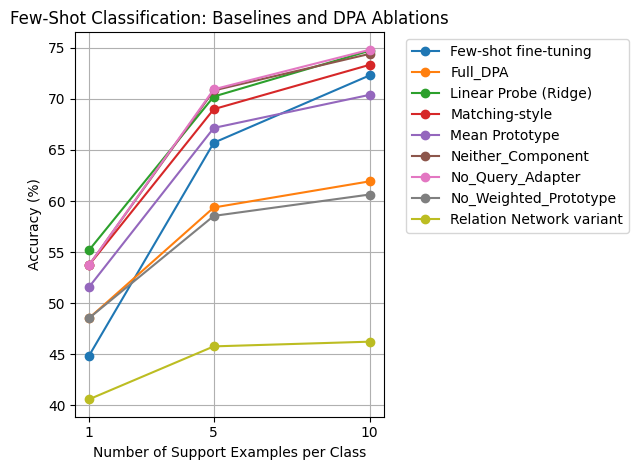

Saved: /content/few_shot_comparison.png


In [142]:

import matplotlib.pyplot as plt

for method, group in results.groupby("method"):
    group = group.sort_values("shot")
    plt.plot(
        group["shot"],
        group["mean_accuracy"],
        marker="o",
        label=method
    )

plt.xticks([1, 5, 10])
plt.xlabel("Number of Support Examples per Class")
plt.ylabel("Accuracy (%)")
plt.title("Few-Shot Classification: Baselines and DPA Ablations")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/few_shot_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: /content/few_shot_comparison.png")


In [143]:

from google.colab import files

files.download("/content/final_comparison_table.csv")
files.download("/content/few_shot_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [144]:

from pathlib import Path

required_files = [
    "/content/consolidated_results.csv",
    "/content/dpa_ablation_results.csv",
    "/content/final_comparison_table.csv",
    "/content/few_shot_comparison.png",
    "/content/resnet18_base_baseline.pth",
]

print("FINAL FILE CHECK\n")

for filename in required_files:
    path = Path(filename)
    if path.exists():
        print(f"FOUND: {path.name} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {path.name}")


FINAL FILE CHECK

FOUND: consolidated_results.csv (2,630 bytes)
FOUND: dpa_ablation_results.csv (968 bytes)
FOUND: final_comparison_table.csv (363 bytes)
FOUND: few_shot_comparison.png (268,737 bytes)
FOUND: resnet18_base_baseline.pth (44,795,467 bytes)


Adapter-scale validation

In [152]:

import numpy as np
import pandas as pd
import random
import torch

# --------------------------------------------------
# 1. DEVICE AND HELPER FUNCTION
# --------------------------------------------------

device = next(dpa_model.parameters()).device

def to_device_tensor(value, dtype):
    """Convert tensors or lists of tensors safely to the model device."""
    if isinstance(value, torch.Tensor):
        return value.to(device=device, dtype=dtype)

    if isinstance(value, (list, tuple)):
        if len(value) > 0 and all(
            isinstance(item, torch.Tensor) for item in value
        ):
            return torch.stack([
                item.to(device=device, dtype=dtype)
                for item in value
            ])

    return torch.as_tensor(value, dtype=dtype, device=device)


# --------------------------------------------------
# 2. CREATE VALIDATION EPISODES
# --------------------------------------------------

random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

validation_episodes = {
    shot: [
        make_episode(base_val_x, base_val_y, shot)
        for _ in range(20)
    ]
    for shot in [1, 5, 10]
}

print("Validation episodes created.")
print("Model device:", device)


# --------------------------------------------------
# 3. TEST ADAPTER SCALES
# --------------------------------------------------

original_scale = dpa_model.shift_scale.detach().clone()
scale_results = []

dpa_model.eval()

try:
    for scale in [0.0, 0.01, 0.05, 0.1, 0.2]:

        with torch.no_grad():
            dpa_model.shift_scale.fill_(scale)

        row = {"adapter_scale": scale}

        for shot in [1, 5, 10]:
            accuracies = []

            with torch.no_grad():
                for supports, queries, targets in validation_episodes[shot]:

                    supports = to_device_tensor(
                        supports, torch.float32
                    )
                    queries = to_device_tensor(
                        queries, torch.float32
                    )
                    targets = to_device_tensor(
                        targets, torch.long
                    )

                    scores, _ = dpa_model(supports, queries)

                    accuracy = (
                        scores.argmax(dim=1) == targets
                    ).float().mean().item() * 100

                    accuracies.append(accuracy)

            row[f"{shot}_shot"] = float(np.mean(accuracies))

        row["average_accuracy"] = np.mean([
            row["1_shot"],
            row["5_shot"],
            row["10_shot"]
        ])

        scale_results.append(row)
        print(f"Finished scale {scale}", flush=True)

finally:
    # Restore the original learned scale
    with torch.no_grad():
        dpa_model.shift_scale.copy_(original_scale)


# --------------------------------------------------
# 4. DISPLAY AND SAVE RESULTS
# --------------------------------------------------

scale_df = pd.DataFrame(scale_results)

best_scale = scale_df.loc[
    scale_df["average_accuracy"].idxmax(),
    "adapter_scale"
]

output_path = "/content/dpa_adapter_scale_validation.csv"
scale_df.to_csv(output_path, index=False)

print("\nADAPTER-SCALE VALIDATION RESULTS")
print(scale_df.to_string(index=False))

print("\nOriginal learned scale:", original_scale.item())
print("Best validation scale:", best_scale)
print("CSV saved:", output_path)


Validation episodes created.
Model device: cuda:0
Finished scale 0.0
Finished scale 0.01
Finished scale 0.05
Finished scale 0.1
Finished scale 0.2

ADAPTER-SCALE VALIDATION RESULTS
 adapter_scale    1_shot    5_shot   10_shot  average_accuracy
          0.00 91.750000 96.000001 95.750001         94.500001
          0.01 93.125001 96.000001 96.125001         95.083334
          0.05 95.125002 97.750000 96.500001         96.458334
          0.10 96.375001 98.500000 97.500001         97.458334
          0.20 97.000001 98.375001 98.000000         97.791667

Original learned scale: 0.16570596396923065
Best validation scale: 0.2
CSV saved: /content/dpa_adapter_scale_validation.csv


In [147]:
#Component validation

In [153]:

import numpy as np
import pandas as pd
import random
import torch

# --------------------------------------------------
# 1. DEVICE AND SAFE TENSOR CONVERSION
# --------------------------------------------------

device = next(dpa_model.parameters()).device

def to_device_tensor(value, dtype):
    if isinstance(value, torch.Tensor):
        return value.to(device=device, dtype=dtype)

    if isinstance(value, (list, tuple)):
        if len(value) > 0 and all(
            isinstance(item, torch.Tensor) for item in value
        ):
            return torch.stack([
                item.to(device=device, dtype=dtype)
                for item in value
            ])

    return torch.as_tensor(value, dtype=dtype, device=device)


# --------------------------------------------------
# 2. COMPONENT VALIDATION FUNCTION
# --------------------------------------------------

def validate_dpa_components(dpa, shot, episodes_count=100):

    dpa.eval()

    variants = {
        "Full_DPA": (True, True),
        "No_Query_Adapter": (True, False),
        "ProtoNet": (False, False)
    }

    # Use the same episodes for all three methods
    random.seed(1234 + shot)

    episodes = [
        make_episode(base_val_x, base_val_y, shot)
        for _ in range(episodes_count)
    ]

    results = []

    with torch.no_grad():
        for method, (use_weight, use_query) in variants.items():

            episode_accuracies = []

            for supports, queries, targets in episodes:

                supports = to_device_tensor(
                    supports, torch.float32
                )
                queries = to_device_tensor(
                    queries, torch.float32
                )
                targets = to_device_tensor(
                    targets, torch.long
                )

                scores, _ = dpa(
                    supports,
                    queries,
                    use_weight=use_weight,
                    use_query=use_query
                )

                accuracy = (
                    scores.argmax(dim=1) == targets
                ).float().mean().item() * 100

                episode_accuracies.append(accuracy)

            values = np.asarray(episode_accuracies)
            mean_accuracy = values.mean()

            margin = (
                1.96 * values.std(ddof=1)
                / np.sqrt(len(values))
            )

            results.append({
                "method": method,
                "shot": shot,
                "mean_accuracy": mean_accuracy,
                "ci_low": mean_accuracy - margin,
                "ci_high": mean_accuracy + margin,
                "episodes": len(values),
                "source": "Base validation"
            })

            print(
                f"{method} | {shot}-shot: "
                f"{mean_accuracy:.2f}% "
                f"[{mean_accuracy-margin:.2f}, "
                f"{mean_accuracy+margin:.2f}]"
            )

    return results


# --------------------------------------------------
# 3. RUN ALL SHOT SETTINGS
# --------------------------------------------------

validation_rows = []

for shot in [1, 5, 10]:
    print(f"\n--- BASE VALIDATION: {shot}-SHOT ---")

    rows = validate_dpa_components(
        dpa_model,
        shot,
        episodes_count=100
    )

    validation_rows.extend(rows)


# --------------------------------------------------
# 4. SAVE RESULTS
# --------------------------------------------------

component_validation_df = pd.DataFrame(validation_rows)

output_path = "/content/dpa_component_validation.csv"

component_validation_df.to_csv(
    output_path,
    index=False
)

print("\nFINAL COMPONENT VALIDATION RESULTS")
print(component_validation_df.to_string(index=False))

print("\nRows:", len(component_validation_df))
print("Saved:", output_path)



--- BASE VALIDATION: 1-SHOT ---
Full_DPA | 1-shot: 96.63% [95.40, 97.85]
No_Query_Adapter | 1-shot: 91.95% [90.28, 93.62]
ProtoNet | 1-shot: 91.95% [90.28, 93.62]

--- BASE VALIDATION: 5-SHOT ---
Full_DPA | 5-shot: 97.73% [97.26, 98.19]
No_Query_Adapter | 5-shot: 95.35% [94.72, 95.98]
ProtoNet | 5-shot: 95.60% [94.99, 96.21]

--- BASE VALIDATION: 10-SHOT ---
Full_DPA | 10-shot: 97.90% [97.47, 98.33]
No_Query_Adapter | 10-shot: 95.95% [95.30, 96.60]
ProtoNet | 10-shot: 95.95% [95.30, 96.60]

FINAL COMPONENT VALIDATION RESULTS
          method  shot  mean_accuracy    ci_low   ci_high  episodes          source
        Full_DPA     1      96.625001 95.396048 97.853954       100 Base validation
No_Query_Adapter     1      91.950001 90.279117 93.620885       100 Base validation
        ProtoNet     1      91.950001 90.279117 93.620885       100 Base validation
        Full_DPA     5      97.725001 97.262526 98.187476       100 Base validation
No_Query_Adapter     5      95.350001 94.719256 

In [154]:

from google.colab import files

files.download("/content/dpa_component_validation.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [155]:
files_to_check = [
    "/content/consolidated_results.csv",
    "/content/final_comparison_table.csv",
    "/content/dpa_ablation_results.csv",
    "/content/dpa_adapter_scale_validation.csv",
    "/content/dpa_component_validation.csv",
    "/content/few_shot_comparison.png",
    "/content/resnet18_base_baseline.pth"
]

for path in files_to_check:
    status = "EXISTS" if os.path.exists(path) else "NOT FOUND"
    print(f"{status}: {os.path.basename(path)}")


EXISTS: consolidated_results.csv
EXISTS: final_comparison_table.csv
EXISTS: dpa_ablation_results.csv
EXISTS: dpa_adapter_scale_validation.csv
EXISTS: dpa_component_validation.csv
EXISTS: few_shot_comparison.png
EXISTS: resnet18_base_baseline.pth
